In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, cross_validate
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import joblib
from google.colab import files

# cores e estilo dos gráficos
AZUL, LARANJA, VERDE, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110,
})

SEED = 42

In [2]:
# Carregar as bases
df = pd.read_csv("/transacoes_historico_2025.csv")

# Converter data diretamente (sem loop para evitar TypeError)
df["datahora_transacao"] = pd.to_datetime(
    df["datahora_transacao"],
    errors="raise"
)

# Organizar cronologicamente
df = df.sort_values("datahora_transacao").reset_index(drop=True)

# Separação temporal
treino = df[df["datahora_transacao"] < "2025-11-01"].copy()

validacao = df[
    (df["datahora_transacao"] >= "2025-11-01") &
    (df["datahora_transacao"] < "2025-12-01")
].copy()

teste = df[
    df["datahora_transacao"] >= "2025-12-01"
].copy()

print(df.shape)
print("Treinamento:", treino.shape)
print("Validação:", validacao.shape)
print("Teste:", teste.shape)

for nome, base in [
    ("Treino", treino),
    ("Validação", validacao),
    ("Teste", teste)
]:
    print(
        f"{nome}: taxa de fraude = "
        f"{base['flag_fraude'].mean():.2%}"
    )

(523525, 15)
Treinamento: (436034, 15)
Validação: (43040, 15)
Teste: (44451, 15)
Treino: taxa de fraude = 3.78%
Validação: taxa de fraude = 3.67%
Teste: taxa de fraude = 5.42%


In [3]:

def criar_atributos_temporais(base):
    dados = base.copy()

    data = dados["datahora_transacao"]

    dados["hora"] = data.dt.hour
    dados["dia_semana"] = data.dt.dayofweek
    dados["dia_mes"] = data.dt.day

    dados["fim_semana"] = (
        dados["dia_semana"] >= 5
    ).astype(int)

    # Representação cíclica do horário
    dados["hora_sin"] = np.sin(
        2 * np.pi * dados["hora"] / 24
    )

    dados["hora_cos"] = np.cos(
        2 * np.pi * dados["hora"] / 24
    )

    # Transformação monetária
    dados["log_valor"] = np.log1p(
        dados["valor_transacao"]
    )

    # Interação identificada na EDA
    dados["noite_dispositivo_novo"] = (
        (dados["turno"] == "noite") &
        (dados["is_new_device"] == True)
    ).astype(int)

    return dados

treino = criar_atributos_temporais(treino)
validacao = criar_atributos_temporais(validacao)
teste = criar_atributos_temporais(teste)
janeiro = criar_atributos_temporais(df)


In [4]:

def criar_historico_cliente(base):
    dados = base.copy()

    dados = dados.sort_values(
        "datahora_transacao",
        kind="stable"
    ).reset_index(drop=True)

    # Quantidade de operações anteriores
    dados["qtd_transacoes_anteriores"] = (
        dados.groupby("nome_cliente").cumcount()
    )

    # Valor médio das operações anteriores
    soma_anterior = (
        dados.groupby("nome_cliente")["valor_transacao"]
        .cumsum() - dados["valor_transacao"]
    )

    quantidade = dados["qtd_transacoes_anteriores"]

    dados["media_valor_anterior"] = np.where(
        quantidade > 0,
        soma_anterior / quantidade.replace(0, np.nan),
        np.nan
    )

    # Distância relativa ao comportamento histórico
    dados["desvio_valor_cliente"] = (
        dados["valor_transacao"] /
        dados["media_valor_anterior"].replace(0, np.nan)
    )

    return dados


In [5]:
numericas = [
    "valor_transacao",
    "score_interno",
    "hora_sin",
    "hora_cos",
    "dia_semana",
    "fim_semana",
    "log_valor",
    "noite_dispositivo_novo"
]

categoricas = [
    "nome_estabelecimento",
    "tipo_estabelecimento",
    "cidade",
    "device_type",
    "is_new_device",
    "turno"
]

preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="median")),
                ("escala", StandardScaler())
            ]),
            numericas
        ),
        (
            "categoricas",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categoricas
        )
    ]
)

features = numericas + categoricas

X_treino = treino[features]
y_treino = treino["flag_fraude"].astype(int)

X_validacao = validacao[features]
y_validacao = validacao["flag_fraude"].astype(int)

X_teste = teste[features]
y_teste = teste["flag_fraude"].astype(int)

print("Variáveis preditoras:", len(features))
print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)
print("Historico:", df.shape)


Variáveis preditoras: 14
Treino: (436034, 14)
Validação: (43040, 14)
Teste: (44451, 14)
Historico: (523525, 15)


In [6]:
features

['valor_transacao',
 'score_interno',
 'hora_sin',
 'hora_cos',
 'dia_semana',
 'fim_semana',
 'log_valor',
 'noite_dispositivo_novo',
 'nome_estabelecimento',
 'tipo_estabelecimento',
 'cidade',
 'device_type',
 'is_new_device',
 'turno']

In [7]:
# Garantir que o conjunto esteja em ordem cronológica
assert treino["datahora_transacao"].is_monotonic_increasing

# Validação cruzada temporal com 4 folds
cv_temporal = TimeSeriesSplit(n_splits=4)

print("Validação cruzada temporal configurada!")

for fold, (idx_treino, idx_val) in enumerate(
    cv_temporal.split(X_treino), start=1
):
    print(f"\nFold {fold}")
    print(f"Treinamento: {len(idx_treino):,} transações")
    print(f"Validação: {len(idx_val):,} transações")

    print(
        "Período de treinamento:",
        treino.iloc[idx_treino]["datahora_transacao"].min(),
        "até",
        treino.iloc[idx_treino]["datahora_transacao"].max()
    )

    print(
        "Período de validação:",
        treino.iloc[idx_val]["datahora_transacao"].min(),
        "até",
        treino.iloc[idx_val]["datahora_transacao"].max()
    )


Validação cruzada temporal configurada!

Fold 1
Treinamento: 87,210 transações
Validação: 87,206 transações
Período de treinamento: 2025-01-01 00:00:00 até 2025-03-02 19:16:00
Período de validação: 2025-03-02 19:17:00 até 2025-05-02 14:21:00

Fold 2
Treinamento: 174,416 transações
Validação: 87,206 transações
Período de treinamento: 2025-01-01 00:00:00 até 2025-05-02 14:21:00
Período de validação: 2025-05-02 14:22:00 até 2025-07-02 09:42:00

Fold 3
Treinamento: 261,622 transações
Validação: 87,206 transações
Período de treinamento: 2025-01-01 00:00:00 até 2025-07-02 09:42:00
Período de validação: 2025-07-02 09:43:00 até 2025-09-01 05:05:00

Fold 4
Treinamento: 348,828 transações
Validação: 87,206 transações
Período de treinamento: 2025-01-01 00:00:00 até 2025-09-01 05:05:00
Período de validação: 2025-09-01 05:06:00 até 2025-10-31 23:59:00


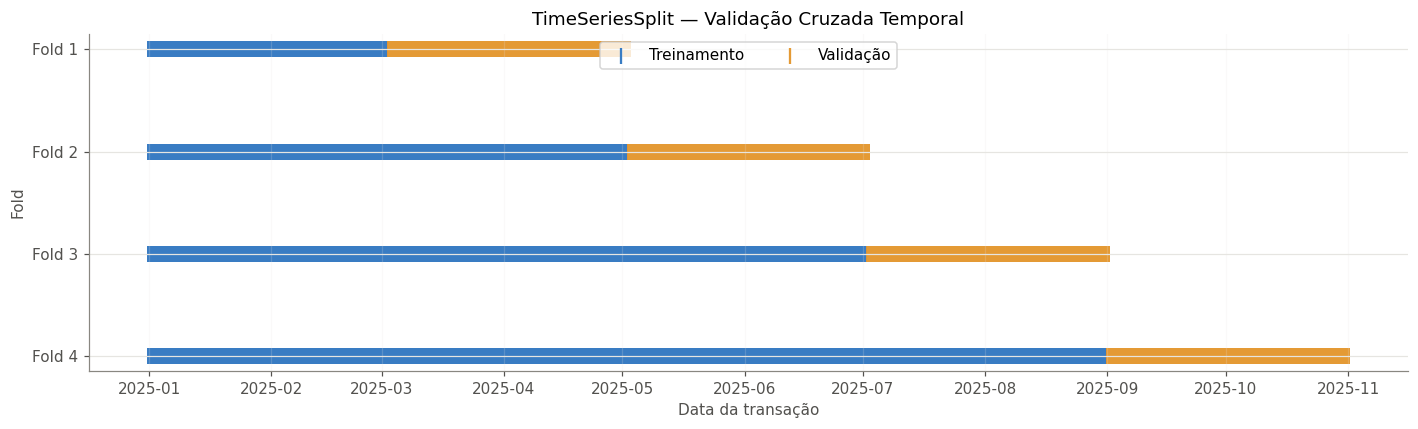

In [8]:
fig, ax = plt.subplots(figsize=(13, 4))

datas_treino = treino["datahora_transacao"].reset_index(drop=True)

for i, (idx_tr, idx_val) in enumerate(
    cv_temporal.split(X_treino)
):
    ax.scatter(
        datas_treino.iloc[idx_tr],
        np.full(len(idx_tr), i),
        color="#397CC3",
        marker="|",
        s=100,
        label="Treinamento" if i == 0 else None
    )

    ax.scatter(
        datas_treino.iloc[idx_val],
        np.full(len(idx_val), i),
        color="#E49A35",
        marker="|",
        s=100,
        label="Validação" if i == 0 else None
    )

ax.set_yticks(range(4))
ax.set_yticklabels([f"Fold {i}" for i in range(1, 5)])

ax.set_title("TimeSeriesSplit — Validação Cruzada Temporal")
ax.set_xlabel("Data da transação")
ax.set_ylabel("Fold")

ax.invert_yaxis()
ax.legend(loc="upper center", ncol=2)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [9]:

from sklearn.dummy import DummyClassifier

# Baseline: sempre prevê fraude (classe 1)
baseline = Pipeline([
    ("preprocessamento", preprocessador),
    ("modelo", DummyClassifier(
        strategy="constant",
        constant=1
    ))
])

# Métricas de avaliação
metricas = {
    "f1": "f1",
    "f1_macro": "f1_macro",

}

# Validação cruzada temporal (4 folds)
resultado_dummy = cross_validate(
    baseline,
    X_treino,
    y_treino,
    cv=cv_temporal,
    scoring=metricas,
    n_jobs=-1
)

# Exibir resultados
for metrica in metricas:
    valores = resultado_dummy[f"test_{metrica}"]

    print(
        f"Baseline {metrica:<12}: "
        f"{valores.mean():.3f} ± {valores.std():.3f}"
    )


Baseline f1          : 0.073 ± 0.001
Baseline f1_macro    : 0.037 ± 0.000


In [10]:
from sklearn.model_selection import cross_val_score

METRICA = "f1_macro"
f1_baseline_cv = cross_val_score(baseline,
                                 X_treino,
                                 y_treino,
                                 cv=cv_temporal,
                                 scoring=METRICA)

In [11]:
# Ajustamos a função para usar o preprocessador correto que lida com variáveis categóricas
def pipeline(modelo):
    return Pipeline([("preprocessamento", preprocessador), ("modelo", modelo)])

modelos = {
    "Regressão Logística": (
        pipeline(LogisticRegression(solver="liblinear", max_iter=5000)),
        {"modelo__C": [0.001, 0.01, 0.1, 1, 10],
         "modelo__class_weight": [None, "balanced"]},
    ),
    "KNN": (
        pipeline(KNeighborsClassifier()),
        {"modelo__n_neighbors": [3, 5, 11, 21],
         "modelo__weights": ["uniform", "distance"]},
    ),
    "SVM": (
        pipeline(SVC(kernel="rbf", random_state=SEED)),
        {"modelo__C": [0.1, 1, 10],
         "modelo__class_weight": [None, "balanced"]},
    ),
    "Árvore de Decisão": (
        pipeline(DecisionTreeClassifier(random_state=SEED)),
        {"modelo__max_depth": [2, 3, 5, 8, None],
         "modelo__min_samples_leaf": [1, 5, 10, 20],
         "modelo__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        pipeline(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
        {"modelo__max_depth": [3, 5, 10, None],
         "modelo__min_samples_leaf": [1, 5, 10],
         "modelo__class_weight": [None, "balanced"]},
    ),
    "Gradient Boosting": (
        pipeline(GradientBoostingClassifier(random_state=SEED)),
        {"modelo__n_estimators": [100, 200],
         "modelo__learning_rate": [0.05, 0.1],
         "modelo__max_depth": [2, 3]},
    ),
}

for nome, (_, grade) in modelos.items():
    n = np.prod([len(v) for v in grade.values()])
    print(f"{nome:<20} {n:>3} combinações × 4 folds = {n * 4:>3} treinos")

Regressão Logística   10 combinações × 4 folds =  40 treinos
KNN                    8 combinações × 4 folds =  32 treinos
SVM                    6 combinações × 4 folds =  24 treinos
Árvore de Decisão     40 combinações × 4 folds = 160 treinos
Random Forest         24 combinações × 4 folds =  96 treinos
Gradient Boosting      8 combinações × 4 folds =  32 treinos


In [12]:
from sklearn.model_selection import train_test_split

X_busca, _, y_busca, _ = train_test_split(
    X_treino,
    y_treino,
    train_size=60000,
    stratify=y_treino,
    random_state=42
)

print(X_busca.shape)
print(y_busca.value_counts(normalize=True))

(60000, 14)
flag_fraude
0    0.962167
1    0.037833
Name: proportion, dtype: float64


In [13]:
from sklearn.model_selection import GridSearchCV
import gc

buscas = {}

for nome, (pipe, grade) in modelos.items():

    print(f"\nTreinando: {nome}")

    busca = GridSearchCV(
        estimator=pipe,
        param_grid=grade,
        cv=cv_temporal,
        scoring=METRICA,
        refit=False,
        n_jobs=2,
        pre_dispatch=2,
        verbose=2,
        error_score="raise"
    )

    busca.fit(X_busca, y_busca)

    buscas[nome] = busca

    print(f"Melhor pontuação: {busca.best_score_:.4f}")
    print(f"Melhores parâmetros: {busca.best_params_}")

    gc.collect()


Treinando: Regressão Logística
Fitting 4 folds for each of 10 candidates, totalling 40 fits
Melhor pontuação: 0.6754
Melhores parâmetros: {'modelo__C': 10, 'modelo__class_weight': None}

Treinando: KNN
Fitting 4 folds for each of 8 candidates, totalling 32 fits
Melhor pontuação: 0.7069
Melhores parâmetros: {'modelo__n_neighbors': 5, 'modelo__weights': 'distance'}

Treinando: SVM
Fitting 4 folds for each of 6 candidates, totalling 24 fits
Melhor pontuação: 0.7716
Melhores parâmetros: {'modelo__C': 10, 'modelo__class_weight': 'balanced'}

Treinando: Árvore de Decisão
Fitting 4 folds for each of 40 candidates, totalling 160 fits
Melhor pontuação: 0.7792
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}

Treinando: Random Forest
Fitting 4 folds for each of 24 candidates, totalling 96 fits
Melhor pontuação: 0.7885
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf':

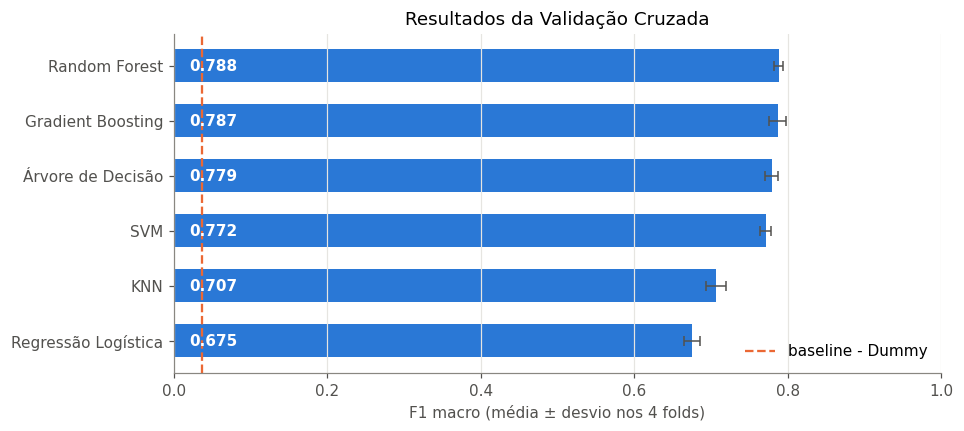

Modelo escolhido pela validação cruzada: Random Forest


In [14]:
# resultados da validação cruzada, média e desvio nos 4 folds, para a melhor combinação de cada modelo
res_cv = pd.DataFrame({
    nome: {"F1 macro (validação)": b.best_score_,
           "desvio": b.cv_results_["std_test_score"][b.best_index_]}
    for nome, b in buscas.items()
}).T.sort_values("F1 macro (validação)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(res_cv.index, res_cv["F1 macro (validação)"], xerr=res_cv["desvio"], color=AZUL, height=0.6,
        error_kw={"ecolor": TINTA, "lw": 1, "capsize": 3})
ax.axvline(f1_baseline_cv.mean(), color=LARANJA, ls="--", lw=1.5, label="baseline - Dummy")
ax.legend(frameon=False, loc="lower right")
for y, v in enumerate(res_cv["F1 macro (validação)"]):
    ax.text(0.02, y, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set(xlabel="F1 macro (média ± desvio nos 4 folds)", xlim=(0, 1), title="Resultados da Validação Cruzada")
ax.grid(axis="y", visible=False)
plt.show()

# o modelo escolhido é o melhor na VALIDAÇÃO, nunca no teste
melhor = res_cv["F1 macro (validação)"].idxmax()
print(f"Modelo escolhido pela validação cruzada: {melhor}")

In [15]:
# ==========================================
# RETREINAMENTO — APENAS RANDOM FOREST
# ==========================================

nome = "Random Forest"

# Recuperar o pipeline já definido
pipe, grade = modelos[nome]

# Recuperar os melhores parâmetros do GridSearchCV
melhores_parametros = buscas[nome].best_params_

# Criar uma cópia independente do pipeline
modelo_rf_final = clone(pipe).set_params(
    **melhores_parametros
)

# Treinar somente a Random Forest
modelo_rf_final.fit(X_treino, y_treino)

# Armazenar apenas o modelo final
finais = {
    "Random Forest": modelo_rf_final
}

print("=== RANDOM FOREST RETREINADA ===")
print("Registros de treinamento:", X_treino.shape[0])
print("Features utilizadas:", X_treino.shape[1])
print("Melhores parâmetros:", melhores_parametros)
print("Treinamento concluído!")


=== RANDOM FOREST RETREINADA ===
Registros de treinamento: 436034
Features utilizadas: 14
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
Treinamento concluído!


In [16]:
# ==========================================
# RETREINAMENTO DOS MODELOS SELECIONADOS
# ==========================================

modelos_selecionados = [
    "Árvore de Decisão",
    "Gradient Boosting"
]

# Preservar a Random Forest já treinada
finais = {
    "Random Forest": modelo_rf_final
}

for nome in modelos_selecionados:

    print(f"\nTreinando: {nome}")

    # Pipeline original
    pipe, _ = modelos[nome]

    # Melhores parâmetros encontrados pelo GridSearchCV
    melhores_parametros = buscas[nome].best_params_

    # Criar modelo independente
    modelo_final = clone(pipe).set_params(
        **melhores_parametros
    )

    # Treinar
    modelo_final.fit(X_treino, y_treino)

    # Armazenar
    finais[nome] = modelo_final

    print("Treinamento concluído!")
    print("Registros:", X_treino.shape[0])
    print("Features:", X_treino.shape[1])
    print("Parâmetros:", melhores_parametros)

print("\n=== MODELOS DISPONÍVEIS ===")
print(list(finais.keys()))



Treinando: Árvore de Decisão
Treinamento concluído!
Registros: 436034
Features: 14
Parâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}

Treinando: Gradient Boosting
Treinamento concluído!
Registros: 436034
Features: 14
Parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 200}

=== MODELOS DISPONÍVEIS ===
['Random Forest', 'Árvore de Decisão', 'Gradient Boosting']


In [17]:
# ==========================================
# COMPARAÇÃO — CONJUNTO DE VALIDAÇÃO
# ==========================================

resultados = []

for nome, modelo in finais.items():

    probabilidades = modelo.predict_proba(
        X_validacao
    )[:, 1]

    previsoes = (
        probabilidades >= 0.50
    ).astype(int)

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(
            y_validacao, previsoes
        ),
        "Precisão": precision_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "F1-score Fraude": f1_score(
            y_validacao, previsoes,
            zero_division=0
        ),
        "F1 Macro": f1_score(
            y_validacao, previsoes,
            average="macro"
        ),
        "Average Precision": average_precision_score(
            y_validacao, probabilidades
        ),
        "ROC-AUC": roc_auc_score(
            y_validacao, probabilidades
        )
    })

df_comparacao = pd.DataFrame(resultados)

df_comparacao = df_comparacao.sort_values(
    "F1-score Fraude",
    ascending=False
)

display(
    df_comparacao.style.format({
        coluna: "{:.4f}"
        for coluna in df_comparacao.columns
        if coluna != "Modelo"
    })
)


,Modelo,Acurácia,Precisão,Recall,F1-score Fraude,F1 Macro,Average Precision,ROC-AUC
0,Random Forest,0.9526,0.4316,0.9184,0.5872,0.7810,0.6381,0.9839
2,Gradient Boosting,0.9733,0.6847,0.5044,0.5809,0.7836,0.6372,0.9843
1,Árvore de Decisão,0.9556,0.4418,0.7930,0.5675,0.7720,0.4388,0.8810


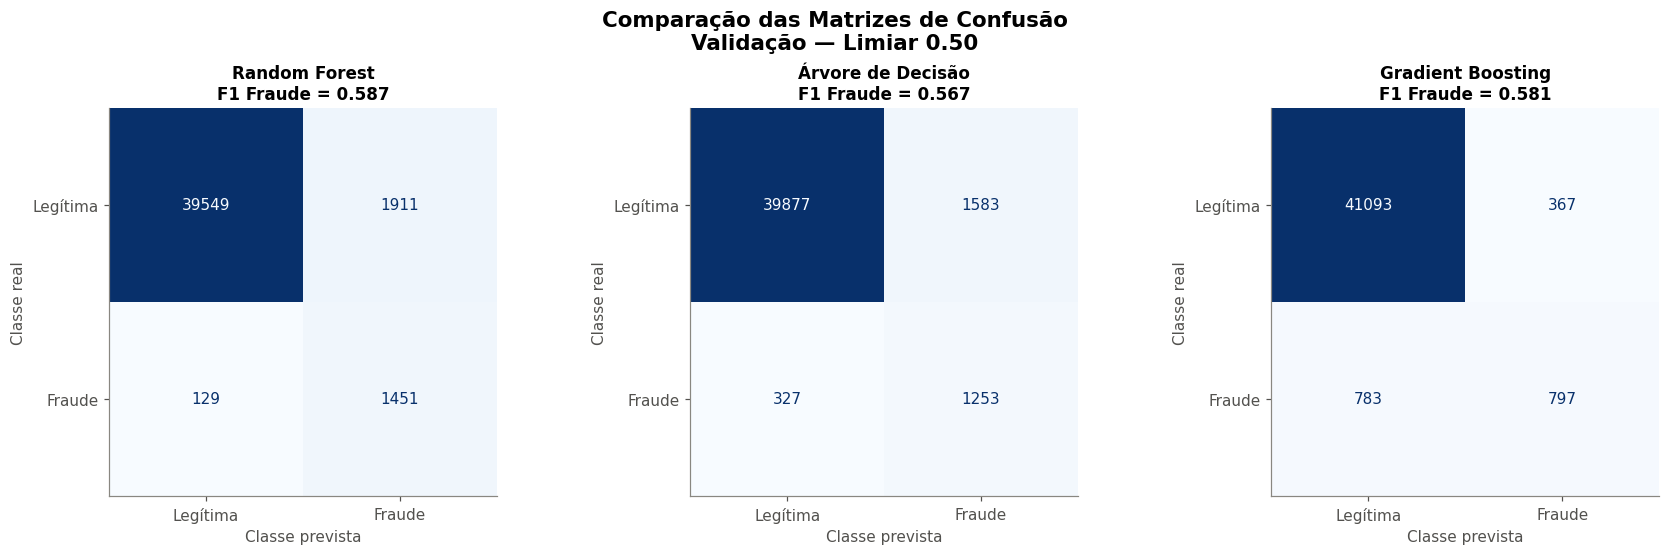

In [18]:
# ==========================================
# MATRIZES DE CONFUSÃO — VALIDAÇÃO
# ==========================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, (nome, modelo) in zip(
    axes,
    finais.items()
):

    prob = modelo.predict_proba(
        X_validacao
    )[:, 1]

    pred = (prob >= 0.50).astype(int)

    cm = confusion_matrix(
        y_validacao,
        pred,
        labels=[0, 1]
    )

    f1 = f1_score(
        y_validacao,
        pred,
        zero_division=0
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legítima", "Fraude"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{nome}\nF1 Fraude = {f1:.3f}",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)

plt.suptitle(
    "Comparação das Matrizes de Confusão\n"
    "Validação — Limiar 0.50",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


=== IMPORTÂNCIA DAS FEATURES ===


,Feature,Importância média,Desvio padrão
13,turno,0.3833,0.0126
3,hora_cos,0.3367,0.0098
9,tipo_estabelecimento,0.2620,0.0074
10,cidade,0.2548,0.0091
2,hora_sin,0.1949,0.0095
8,nome_estabelecimento,0.1789,0.0061
12,is_new_device,0.1578,0.0156
6,log_valor,0.1317,0.0074
0,valor_transacao,0.1300,0.0083
11,device_type,0.1203,0.0119


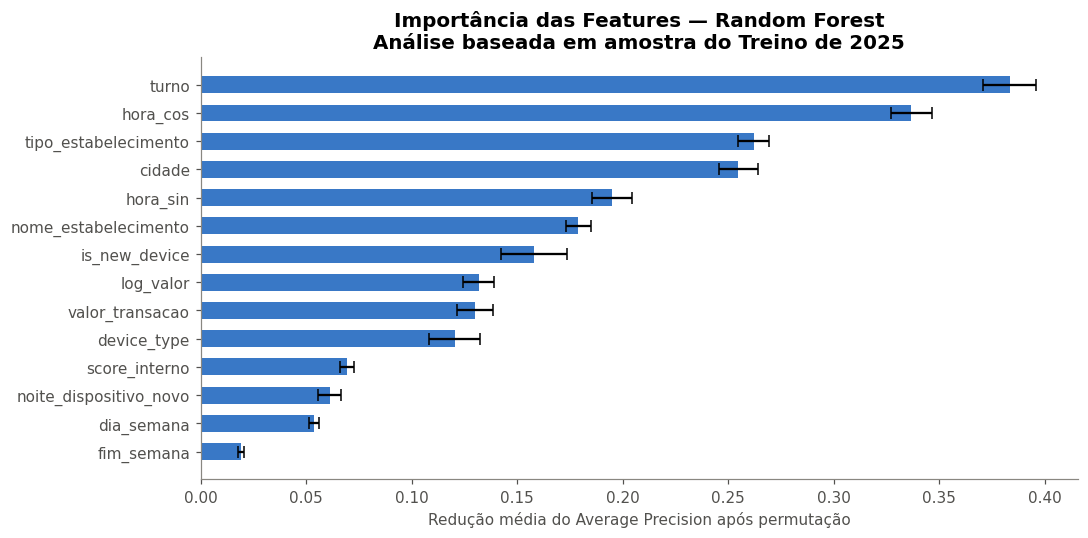

In [19]:
# ==========================================
# IMPORTÂNCIA DAS FEATURES — RANDOM FOREST
# ==========================================

# Selecionar Random Forest
modelo_rf = finais["Random Forest"]

# Features utilizadas no modelo (corrigido de features_cidade para features)
FEATURES = list(features)

# Como o conjunto de validação externa está vazio, usamos o treino para a análise
X_importancia = X_treino[FEATURES]
y_importancia = y_treino

# Amostra para reduzir custo computacional
amostra = X_importancia.sample(
    n=min(10000, len(X_importancia)),
    random_state=42
)

y_amostra = y_importancia.loc[amostra.index]

# Calcular importância por permutação
imp = permutation_importance(
    estimator=modelo_rf,
    X=amostra,
    y=y_amostra,
    scoring="average_precision",
    n_repeats=10,
    random_state=15,
    n_jobs=1
)

# Organizar resultados
importancia = pd.DataFrame({
    "Feature": FEATURES,
    "Importância média": imp.importances_mean,
    "Desvio padrão": imp.importances_std
}).sort_values(
    "Importância média",
    ascending=False
)

print("=== IMPORTÂNCIA DAS FEATURES ===")

display(
    importancia.style.format({
        "Importância média": "{:.4f}",
        "Desvio padrão": "{:.4f}"
    })
)

# ==========================================
# GRÁFICO
# ==========================================

top = importancia.sort_values(
    "Importância média"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    top["Feature"],
    top["Importância média"],
    xerr=top["Desvio padrão"],
    color="#3978C6",
    height=0.6,
    capsize=4
)

ax.axvline(
    0,
    color="gray",
    linewidth=1
)

ax.set_xlabel(
    "Redução média do Average Precision após permutação"
)

ax.set_title(
    "Importância das Features — Random Forest\n"
    "Análise baseada em amostra do Treino de 2025",
    fontsize=13,
    fontweight="bold"
)

ax.grid(False)

plt.tight_layout()
plt.show()

In [22]:
# ==========================================
# MELHOR LIMIAR COM RECALL MÍNIMO DE 90%
# ==========================================

# Obter as probabilidades para a classe positiva do modelo Random Forest
modelo_rf = finais["Random Forest"]
probabilidades_rf = modelo_rf.predict_proba(X_validacao)[:, 1]

# Gerar candidatos a limiares de 0.01 a 0.99
limiares_teste = np.arange(0.01, 1.00, 0.01)
resultados_limiares = []

for limiar in limiares_teste:
    pred_limiar = (probabilidades_rf >= limiar).astype(int)
    precisao = precision_score(y_validacao, pred_limiar, zero_division=0)
    recall = recall_score(y_validacao, pred_limiar, zero_division=0)
    f1 = f1_score(y_validacao, pred_limiar, zero_division=0)

    resultados_limiares.append({
        "Limiar": limiar,
        "Precisão": precisao,
        "Recall": recall,
        "F1-score": f1
    })

# Definir o DataFrame de limiares que estava faltando
df_limiares = pd.DataFrame(resultados_limiares)

candidatos = df_limiares[
    df_limiares["Recall"] >= 0.90
].copy()

if not candidatos.empty:

    candidatos = candidatos.sort_values(
        ["Precisão", "F1-score"],
        ascending=False
    )

    melhor_recall90 = candidatos.iloc[0]

    print("=== MELHOR CONFIGURAÇÃO COM RECALL >= 90% ===")

    display(
        candidatos.head(10).round(4)
    )

    print(
        "Limiar recomendado:",
        melhor_recall90["Limiar"]
    )

else:
    print(
        "Nenhum limiar testado atingiu recall de 90%."
    )

=== MELHOR CONFIGURAÇÃO COM RECALL >= 90% ===


,Limiar,Precisão,Recall,F1-score
52,0.53,0.4410,0.9038,0.5928
51,0.52,0.4377,0.9095,0.5910
50,0.51,0.4345,0.9133,0.5889
49,0.50,0.4316,0.9184,0.5872
48,0.49,0.4277,0.9228,0.5845
47,0.48,0.4259,0.9291,0.5840
46,0.47,0.4216,0.9329,0.5808
45,0.46,0.4185,0.9361,0.5784
44,0.45,0.4173,0.9443,0.5789
43,0.44,0.4165,0.9532,0.5797


Limiar recomendado: 0.53


In [ ]:
artefato_final = {
    "modelo": modelo_rf_final,
    "features": list(X_treino.columns),
    "limiar": limiar_rf,
    "algoritmo": "Random Forest",
    "criterio_selecao": "Recall >= 90% na validação"
}

nome_arquivo = "random_forest_final_limiar_053.joblib"

joblib.dump(artefato_final, nome_arquivo)

print("Modelo salvo com sucesso!")
print("Limiar selecionado:", artefato_final["limiar"])

files.download(nome_arquivo)
